# Algoritmos de Procura

Trabalho realizado por:
- Francisco Lopes nº111358
- Raul Azevedo nº111479

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import time

## Exercício 1

### Alínea a - Gerar um padrão aleatório de bits 

A função `random_pattern` gera um padrão aleatório de **n** bits.

O resultado é devolvido como uma **string** de 0s e 1s.

In [9]:
def random_pattern(n, rng):
    bits = rng.integers(0, 2, size=n)
    return ''.join(map(str, bits))
    

### Alínea b - Força Bruta

A função `brute_force` implementa o algoritmo de procura por força bruta. Esta gera padrões aleatórios até encontrar uma correspondência exata com o padrão-alvo.

**Funcionamento:**
1. Guarda o instante inicial e coloca o contador de tentativas `attempts` a zero.
2. Em cada iteração verifica se o `deadline` foi atingido. Se sim, lança um `TimeoutError`.
3. Incrementa o contador `attempts` e gera um palpite com `random_pattern`. Se for igual ao alvo, o ciclo termina.
4. Devolve o número de tentativas e o tempo gasto

In [ ]:
def brute_force(target, rng, deadline):
    n = len(target)
    attempts = 0
    start = time.perf_counter()
    while True:
        if time.perf_counter() >= deadline:
            raise TimeoutError

        attempts += 1
        if random_pattern(n, rng) == target:
            break
        
    return attempts, time.perf_counter() - start

A função `run_experiment` implementa a força bruta para diferentes tamanhos do target e guarda os seus respetivos resultados.

**Funcionamento**
1. Para cada `n` da lista `SIZES`, define um `deadline` de 15 minutos (`TIME_LIMIT`) que se aplica ao conjunto dos 30 trials desse `n`.
2. Faz 30 trials, um por seed de `SEEDS`. Em cada um, cria um gerador com essa seed, gera o target e chama `brute_force`. O uso de seeds fixas torna a experiência reproduzível.
3. Guarda o número de tentativas e o tempo de cada trial em duas listas, que depois servem para os box-plots.
4. Se o `TimeoutError` for lançado, o `n` em causa é descartado e a experiência pára, visto que tamanhos maiores seriam ainda mais lentos.
5. Devolve o dicionário `results`, com chave `n` e valor `(attempts, times)`.

In [4]:
SEEDS = list(range(30))
TIME_LIMIT = 15 * 60 # 15 minutos em segundos
SIZES = [2, 4, 8, 12, 16, 20, 24, 28, 32]

def run_experiment(sizes):
    results = {}
    for n in sizes:
        attempts, times = [], []
        deadline = time.perf_counter() + TIME_LIMIT
        
        try:
            for seed in SEEDS:
                rng = np.random.default_rng(seed)
                target = random_pattern(n, rng)

                a, t = brute_force(target, rng, deadline)

                attempts.append(a)
                times.append(t)

        except TimeoutError:
            print(f"Limite de tempo excedido para n={n}.")
            break

        results[n] = (attempts, times)
        total_time = sum(times)
        print(f"n={n:2d} | média tentativas={np.mean(attempts):,.0f} | tempo total={total_time:.1f}s")

    return results

results = run_experiment(SIZES)

n= 2 | média tentativas=4 | tempo total=0.0s
n= 4 | média tentativas=19 | tempo total=0.0s
n= 8 | média tentativas=348 | tempo total=0.1s
n=12 | média tentativas=3,254 | tempo total=0.7s
n=16 | média tentativas=64,490 | tempo total=14.0s
n=20 | média tentativas=904,935 | tempo total=214.0s
Limite de tempo excedido para n=24.


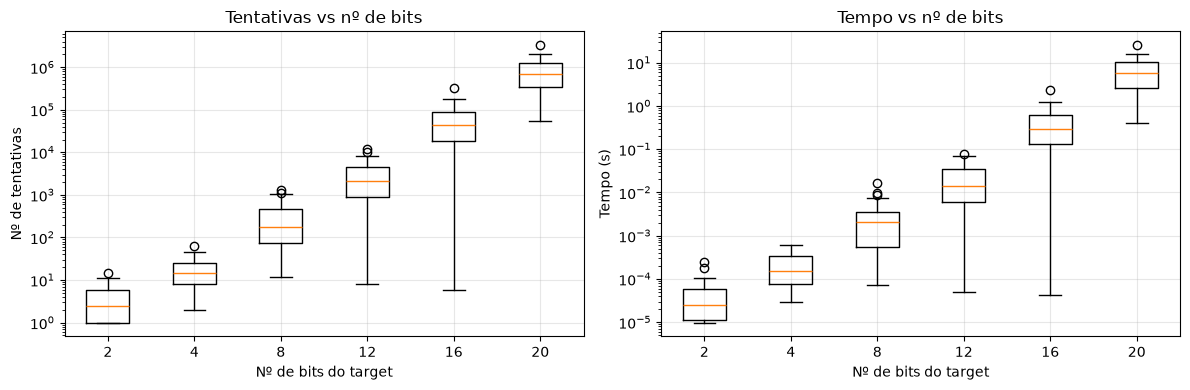

In [6]:
def plot_results(results):
    sizes = list(results)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    configs = [(0, "Nº de tentativas", "Tentativas vs nº de bits"),
               (1, "Tempo (s)", "Tempo vs nº de bits")]
    for ax, (idx, ylabel, title) in zip(axes, configs):
        ax.boxplot([results[n][idx] for n in sizes], positions=range(len(sizes)))
        ax.set_xticks(range(len(sizes)))
        ax.set_xticklabels(sizes)
        ax.set_yscale("log")
        ax.set_xlabel("Nº de bits do target")
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_results(results)

**Resultados e Observações - Força bruta**

| n (bits) | Média de tentativas | Tempo total (30 trials) |
|---|---|---|
| 2 | 4 | ~0 s |
| 4 | 19 | ~0 s |
| 8 | 348 | 0.1 s |
| 12 | 3 254 | 0.7 s |
| 16 | 64 490 | 14.0 s |
| 20 | 904 935 | 214.0 s |
| 24 | - | limite de 15 min excedido |

**Tentativas:** O número de tentativas cresce de forma exponencial com o tamanho do target: de 4 tentativas em média com 2 bits passa para cerca de 905 mil com 20 bits. 

**Tempo:** O tempo acompanha o número de tentativas, e os dois gráficos têm uma forma muito semelhante. Passa de valores desprezáveis (n ≤ 4) para 14s com 16 bits e 214s com 20 bits, no conjunto dos 30 trials.

**Dispersão:** Os resultados variam bastante entre trials do mesmo tamanho. Para n = 12 e n = 16 há trials que acertam com muito poucas tentativas (bigodes inferiores longos), e em vários tamanhos existem *outliers* acima da caixa. 

**Escolha do tamanho:** O maior padrão que completou os 30 trials em tempo razoável foi **n = 20** (214 s), e será o tamanho usado nos exercícios seguintes.

## Exercício 2

### Alínea a - Fitness

A função `fitness` mede a qualidade de um palpite através do número de bits que coincidem com o alvo.

- Varia entre 0 (todos os bits errados) a `n` (padrão igual ao target)

In [7]:
def fitness(guess, target):
    return sum(g == t for g, t in zip(guess, target))

### Alínea b - Hill Climbing

A função `mutate` escolhe aleatoriamente uma posição e inverte o seu respetivo bit; devolve uma cópia do padrão com esse bit invertido

In [11]:
def mutate(pattern, rng):
    i = rng.integers(len(pattern))
    flipped = '1' if pattern[i] == '0' else '0'
    return pattern[:i] + flipped + pattern[i+1:]

A função `hill_climbing` inicializa um padrão de forma aleatória e melhora-o de forma gradual:

1. Gera um candidato através de uma mutação (bit flip mutation) do padrão atual.
2. Calcula a fitness do candidato e compara-a com a do padrão atual.
3. Só aceita o candidato se a fitness for superior; caso contrário, descarta-o e mantém o padrão atual.

A função pára ao fim de `max_mutations` ou caso o padrão seja igual ao `target`;

A função devolve o número de mutações que foram realizadas, o tempo gasto e se o `target` foi encontrado.

In [20]:
MAX_MUTATIONS = 1000

def hill_climbing(target, rng, max_mutations=MAX_MUTATIONS):
    current = random_pattern(len(target), rng)
    current_fitness = fitness(current, target)
    mutations = 0
    start = time.perf_counter()

    while mutations < max_mutations and current != target:
        candidate = mutate(current, rng)
        mutations += 1
        candidate_fitness = fitness(candidate, target)

        if candidate_fitness > current_fitness:
            current, current_fitness = candidate, candidate_fitness

    return mutations, time.perf_counter() - start, current == target

In [21]:
def run_hill_climbing(n):
    mutations, times, found = [], [], []
    for seed in SEEDS:
        rng = np.random.default_rng(seed)
        target = random_pattern(n, rng)
        m, t, f = hill_climbing(target, rng)

        mutations.append(m)
        times.append(t)
        found.append(f)

    print(f"n={n} | média mutações={np.mean(mutations):.1f} | "
        f"tempo total={sum(times):.3f}s | alvo encontrado em {sum(found)}/30")

    return mutations, times


N = 20
hc_mutations, hc_times = run_hill_climbing(N)


n=20 | média mutações=59.0 | tempo total=0.007s | alvo encontrado em 30/30


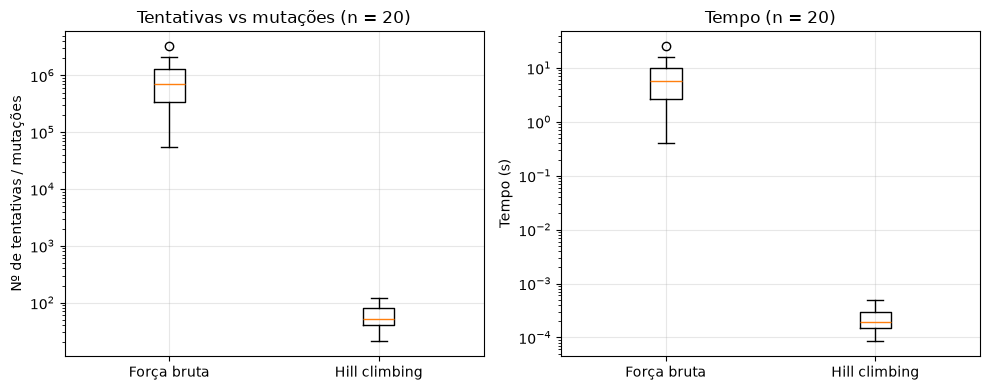

In [22]:
def plot_comparison(bf_results, hc_mutations, hc_times):
    bf_attempts, bf_times = bf_results
    labels = ["Força bruta", "Hill climbing"]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    configs = [
        (axes[0], [bf_attempts, hc_mutations], "Nº de tentativas / mutações", "Tentativas vs mutações"),
        (axes[1], [bf_times, hc_times], "Tempo (s)", "Tempo"),
    ]
    for ax, data, ylabel, title in configs:
        ax.boxplot(data, tick_labels=labels)
        ax.set_yscale("log")
        ax.set_ylabel(ylabel)
        ax.set_title(f"{title} (n = {N})")
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_comparison(results[N], hc_mutations, hc_times)

**Resultados e observações - Hill climbing vs força bruta (n = 20)**

| Método | Média de tentativas / mutações | Tempo total (30 trials) | Target encontrado |
|---|---|---|---|
| Força bruta | 904 935 | 214.0 s | 30/30 |
| Hill climbing | 59 | 0.007 s | 30/30 |

**Número de tentativas:** O hill climbing precisa, em média, de 59 mutações para encontrar o alvo, contra cerca de 905 mil tentativas na força bruta, ou seja, quase quatro ordens de grandeza a menos. 

**Tempo:** A diferença no tempo acompanha a do número de tentativas. No conjunto dos 30 trials, passa-se de 214s para 0.007s.

**Dispersão:** O hill climbing tem uma variação muito menor, enquanto na força bruta se estendem por mais de duas ordens de grandeza.

**Conclusão:** Para n = 20, o hill climbing é muito mais eficiente do que a força bruta, tanto em número de candidatos avaliados como em tempo, e com resultados mais estáveis entre trials.

### Alínea c - Máximo Local

A função `fitness` (número de bits coincidentes) e a função `mutate` (flip bit mutation) garante que não haja máximos locais, isto é, padrões que não correspondem ao `target` mas os seus vizinhos (padrões com um bit de distância) tem fitness igual ou inferior. 

Qualquer padrão diferente do `target` tem pelo menos um bit errado, e inverter esse bit aumenta o fitness em exatamente 1 valor. Assim, para qualquer padrão que não seja o `target` existe sempre uma mutação que melhora o fitness, pelo que o algoritmo nunca fica preso e o único máximo é o global (o `target`).

Os resultados confirmam-no: o hill climbing encontrou o `target`, que corresponde ao máximo global, em 30/30 trials, sem nunca esgotar o limite de 1000 mutações. 

## Exercício 3

### Alínea a - algoritmo evolutivo com mutação

A função `evolutionary_search` evolui uma população de 100 padrões:
1. Avalia a fitness de cada padrão e seleciona os **30% melhores**.
2. Gera os restantes 70% por **mutação** de um bit de um dos melhores, escolhido ao acaso.
3. Repete o processo com a nova população (os 30 melhores mais os 70 mutados).

Pára quando encontra o `target` ou quando o melhor fitness não melhora durante 10 gerações seguidas (`PATIENCE`).

Devolve o número de avaliações de fitness, o tempo, se o `target` foi encontrado e o número de gerações.

Para comparar de forma justa com os métodos anteriores, usa-se o mesmo `n`, os mesmos alvos e 30 trials, e contam-se os candidatos avaliados em cada método (tentativas, mutações e avaliações de fitness).

In [ ]:
POPULATION_SIZE = 100
ELITE = 0.30
PATIENCE = 10 # número de gerações sem melhoria

def evolutionay_search(target, rng, population_size=POPULATION_SIZE, elite_frac=ELITE, patience=PATIENCE):
    n = len(target)
    n_elite = int(population_size * elite_frac)
    start = time.perf_counter()

    population = [random_pattern(n, rng) for _ in range(population_size)]
    scores = [fitness(p, target) for p in population]

    evaluations = population_size
    generations = 0
    best_fit, stagnat = -1, 0

    while True:
        order = np.argsort(scores)[::-1] # ordena os scores de forma descrescente
        elite = [population[i] for i in order[:n_elite]] # seleciona os melhores indivíduos (os melhores 30% da população) 
        elite_scores = [scores[i] for i in order[:n_elite]] # seleciona a pontuação dos melhores indivíduos 
        best = elite_scores[0] # pontuação do melhor individuo

        # critérios de paragem
        if best == n:
            break
        if best > best_fit:
            best_fit, stagnat = best, 0
        else:
            stagnat += 1
        if stagnat >= patience:
            break

        # gerar os restantes por mutação dos melhores
        children = [mutate(elite[rng.integers(n_elite)], rng) for _ in range(population_size - n_elite)]                
        child_scores = [fitness(c, target) for c in children]
        evaluations += len(children)
        population = elite + children
        scores = elite_scores + child_scores
        generations += 1

    return evaluations, time.perf_counter() - start, best == n, generations

In [45]:
def run_evolutionary(n):
    evaluations, times, found, generations = [], [], [], []
    for seed in SEEDS:
        rng = np.random.default_rng(seed)
        target = random_pattern(n, rng)
        e, t, f, g = evolutionay_search(target, rng)

        evaluations.append(e)
        times.append(t) 
        found.append(f)
        generations.append(g)

    print(f"n={n} | média avaliações={np.mean(evaluations):.0f} | média gerações={np.mean(generations):.1f} | "
        f"tempo total={sum(times):.3f}s | target encontrado em {sum(found)}/30")
    
    return evaluations, times


ea_evals, ea_times = run_evolutionary(N)

n=20 | média avaliações=723 | média gerações=8.9 | tempo total=0.133s | target encontrado em 30/30


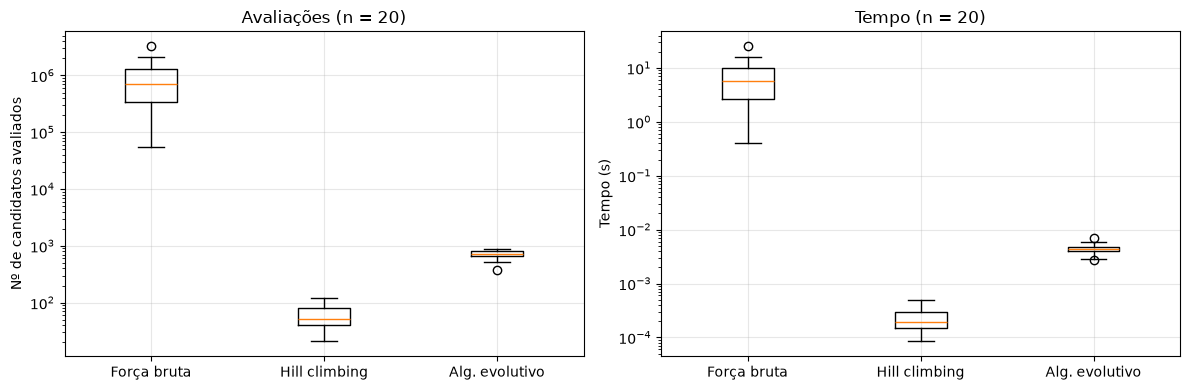

In [46]:
def plot_comparison_3(bf, hc, ea):
    labels = ["Força bruta", "Hill climbing", "Alg. evolutivo"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    configs = [
        (axes[0], [bf[0], hc[0], ea[0]], "Nº de candidatos avaliados", "Avaliações"),
        (axes[1], [bf[1], hc[1], ea[1]], "Tempo (s)", "Tempo"),
    ]
    for ax, data, ylabel, title in configs:
        ax.boxplot(data, tick_labels=labels)
        ax.set_yscale("log")
        ax.set_ylabel(ylabel)
        ax.set_title(f"{title} (n = {N})")
        ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_comparison_3(results[N], (hc_mutations, hc_times), (ea_evals, ea_times))

**Resultados e observações - Algoritmo evolutivo (mutação) vs métodos anteriores (n = 20)**

| Método | Média | Tempo total (30 trials) | Target encontrado |
|---|---|---|---|
| Força bruta | 904 935 | 214.0 s | 30/30 |
| Hill climbing | 59 | 0.007 s | 30/30 |
| Algoritmo evolutivo (mutação) | 723 | 0.133 s | 30/30 |

**Avaliações:** O algoritmo evolutivo precisou, em média, de 723 avaliações de fitness (cerca de 8.9 gerações), cerca de 1250 vezes menos do que a força bruta. Face ao hill climbing, usa cerca de 12 vezes mais avaliações, por isso este continua a ser o método mais eficiente neste problema.

**Tempo:** O algoritmo evolutivo foi aproximadamente 1600 vezes mais rápido do que a força bruta (0.133s contra 214s no conjunto dos 30 trials). Houve uma diferença residual comparativamente com o hill climbing.

**Dispersão:** O algoritmo evolutivo foi o método com resultados mais estáveis: a caixa é muito estreita, com valores concentrados em torno das 700 avaliações. 

**Conclusão:** Para n = 20, tanto o hill climbing como o algoritmo evolutivo são várias ordens de grandeza mais eficientes do que a força bruta. O algoritmo evolutivo é o mais regular entre trials.

### Alínea b - Crossover

A função `crossover` implementa um crossover de um ponto: sorteia um ponto de corte e o filho herda os bits do primeiro pai até esse ponto e os do segundo pai a partir dele.

In [52]:
def crossover(p1, p2, rng):
    point = rng.integers(1, len(p1))
    return p1[:point] + p2[point:]

A função `make_child` define a forma como os filhos vão ser gerados: mutação, crossover ou ambos.

In [53]:
def make_child(elite, rng, use_mutation, use_crossover):
    n_elite = len(elite)
    if use_crossover:
        i, j = rng.choice(n_elite, size=2, replace=False)  # escolhe dois pais distintos 
        child = crossover(elite[i], elite[j], rng)
        if use_mutation:
            child = mutate(child, rng)

    else:
        child = mutate(elite[rng.integers(n_elite)], rng)

    return child

A função evolutionary_search_v2 foi generalizada para gerar filhos de três formas:
- **só mutação:** mutação de um dos melhores;
- **só crossover:** crossover de dois dos melhores, escolhidos ao acaso e distintos;
- **mutação e crossover:** crossover seguido de mutação do filho.

O resto do processo é igual à função `evolutionary_search`.

In [54]:
def evolutionay_search_v2(target, rng, use_mutation=True, use_crossover=False,
                          population_size=POPULATION_SIZE, elite_frac=ELITE, patience=PATIENCE):
    n = len(target)
    n_elite = int(population_size * elite_frac)
    start = time.perf_counter()

    population = [random_pattern(n, rng) for _ in range(population_size)]
    scores = [fitness(p, target) for p in population]

    evaluations = population_size
    generations = 0
    best_fit, stagnat = -1, 0

    while True:
        order = np.argsort(scores)[::-1] # ordena os scores de forma descrescente
        elite = [population[i] for i in order[:n_elite]] # seleciona os melhores indivíduos (os melhores 30% da população) 
        elite_scores = [scores[i] for i in order[:n_elite]] # seleciona a pontuação dos melhores indivíduos 
        best = elite_scores[0] # pontuação do melhor individuo

        # critérios de paragem
        if best == n:
            break
        if best > best_fit:
            best_fit, stagnat = best, 0
        else:
            stagnat += 1
        if stagnat >= patience:
            break

        # gerar os restantes por mutação e/ou crossover apartir dos melhores
        children = [make_child(elite, rng, use_mutation, use_crossover) for _ in range(population_size - n_elite)]                
        child_scores = [fitness(c, target) for c in children]
        evaluations += len(children)
        population = elite + children
        scores = elite_scores + child_scores
        generations += 1

    return evaluations, time.perf_counter() - start, best == n, generations

In [61]:
def run_variant(n, use_mutation, use_crossover):
    evaluations, times, found, generations = [], [], [], []
    for seed in SEEDS:
        rng = np.random.default_rng(seed)
        target = random_pattern(n, rng)
        e, t, f, g = evolutionay_search_v2(target, rng, use_mutation, use_crossover)
        evaluations.append(e); times.append(t); found.append(f); generations.append(g)
    return evaluations, times, found, generations

variants = {
    "Só mutação":          (True,  False),
    "Só crossover":        (False, True),
    "Mutação + crossover": (True,  True),
}

ea_results = {}
for name, (mut, cross) in variants.items():
    evaluations, times, found, generations = run_variant(N, mut, cross)
    ea_results[name] = (evaluations, times)
    print(f"{name:20s} | média avaliações={np.mean(evaluations):.0f} | média gerações={np.mean(generations):.1f} | "
          f"tempo total={sum(times):.3f}s | target encontrado em {sum(found)}/30")

Só mutação           | média avaliações=723 | média gerações=8.9 | tempo total=0.152s | target encontrado em 30/30
Só crossover         | média avaliações=522 | média gerações=6.0 | tempo total=0.189s | target encontrado em 29/30
Mutação + crossover  | média avaliações=539 | média gerações=6.3 | tempo total=0.254s | target encontrado em 30/30


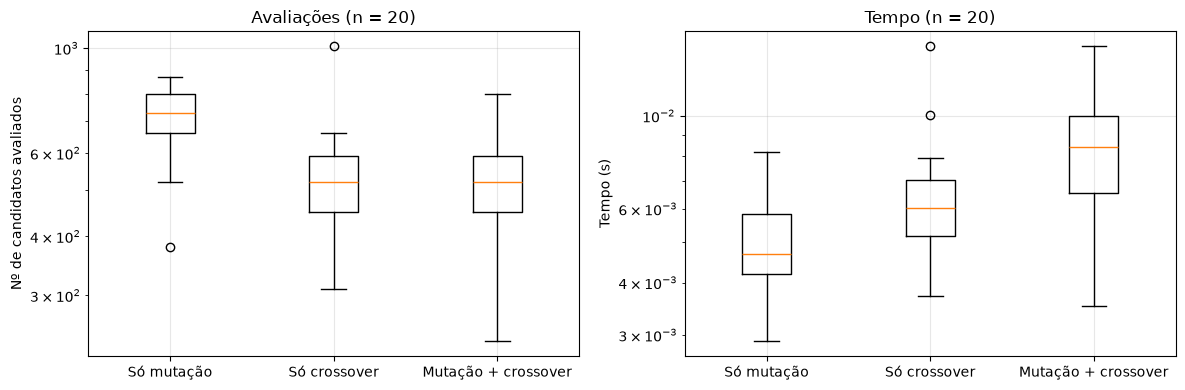

In [62]:
def plot_variants(ea_results):
    labels = list(ea_results)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    configs = [
        (axes[0], [ea_results[k][0] for k in labels], "Nº de candidatos avaliados", "Avaliações"),
        (axes[1], [ea_results[k][1] for k in labels], "Tempo (s)", "Tempo"),
    ]
    for ax, data, ylabel, title in configs:
        ax.boxplot(data, tick_labels=labels)
        ax.set_yscale("log")
        ax.set_ylabel(ylabel)
        ax.set_title(f"{title} (n = {N})")
        ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_variants(ea_results)

**Resultados e Observações - Mutação vs crossover vs mutação + crossover (n = 20)**

| Variante | Média de avaliações | Média de gerações | Tempo total (30 trials) | Alvo encontrado |
|---|---|---|---|---|
| Só mutação | 723 | 8.9 | 0.152 s | 30/30 |
| Só crossover | 522 | 6.0 | 0.189 s | 29/30 |
| Mutação + crossover | 539 | 6.3 | 0.254 s | 30/30 |

**Avaliações e gerações:** As duas variantes com crossover precisam de menos avaliações e de menos gerações do que a variante só com mutação. Entre "só crossover" e "mutação + crossover" a diferença é mínima, e as medianas são praticamente iguais.

**Tempo:** As diferenças de tempo são residuais.

**Dispersão:** A variante só com mutação é a mais regular. A combinação de mutação e crossover é a que mais varia. 

**Taxa de sucesso:** Só a variante com crossover sem mutação falhou um trial (29/30), ficando parada sem encontrar o alvo. O crossover apenas recombina bits que já existem na população, pelo que, se um bit correto se perder, não há forma de o recuperar. As variantes com mutação encontraram sempre o alvo.

**Conclusão:** O crossover reduz o número de avaliações e de gerações necessárias, mas não compensa em tempo de execução para n = 20, e usado sozinho perde fiabilidade. A combinação de mutação e crossover é a melhor solução de compromisso em número de avaliações, mantendo 30/30 de sucesso. A variante só com mutação é a mais estável.

## Exercício 4

Quando o tamanho do target é desconhecido (entre 2 e 32), os candidatos passam a ter comprimento variável e as três componentes foram adaptadas:

- **Fitness (`fitness_var`):** `32 − distância`, onde a distância soma os bits diferentes nas posições comuns e a diferença de comprimentos. O máximo (32) só é atingido quando o padrão é igual ao target, pelo que a pesquisa pode parar sem conhecer o seu tamanho.
- **Mutação (`mutate_var`):** inverte um bit, acrescenta um bit no fim ou remove o último, escolhendo a operação ao acaso. As alterações de comprimento são feitas no fim para não deslocar os bits já corretos.
- **Crossover (`crossover_var`):** um ponto de corte em cada pai, de modo a que o filho possa ter um comprimento diferente (truncado a 32 bits).

In [1]:
MIN_LEN, MAX_LEN = 2, 32

def random_pattern_var(rng):
    size = rng.integers(MIN_LEN, MAX_LEN + 1)
    return random_pattern(size, rng)

def fitness_var(guess, target):
    common = min(len(guess), len(target))
    mismatches = sum(guess[i] != target[i] for i in range(common)) # conta o número de bits diferentes nas posições comuns
    distance = mismatches + abs(len(guess) - len(target)) # erros nas posições comuns + diferença de tamanho
    return MAX_LEN - distance 

def mutate_var(pattern, rng):
    operation = rng.choice(["flip", "add", "remove"])
    if operation == "add" and len(pattern) < MAX_LEN:
        return pattern + str(rng.integers(2)) # acrescenta um bit no fim
    if operation == "remove" and len(pattern) > MIN_LEN:
        return pattern[:-1] # remove o último bit
    return mutate(pattern, rng) # inverte um bit 

def crossover_var(p1, p2, rng):
    c1 = rng.integers(1, len(p1)) # um corte em cada pai
    c2 = rng.integers(1, len(p2))
    return (p1[:c1] + p2[c2:])[:MAX_LEN]  # o filho pode ter outro comprimento

A função `evolutionary_search_var` segue o mesmo processo do algoritmo evolutivo anterior (população de 100 padrões, seleção dos 30% melhores, geração dos restantes 70% e paragem por estagnação), mas usa as versões adaptadas a padrões de comprimento variável:

- **`random_pattern_var`**, para gerar a população inicial com comprimentos aleatórios entre 2 e 32;
- **`fitness_var`**, para avaliar os candidatos;
- **`mutate_var`** e **`crossover_var`**, para gerar os filhos, através de `make_child_var`.

A pesquisa pára quando a fitness atinge o máximo (`MAX_LEN`), ou seja, quando o padrão é igual ao target, ou quando a melhor fitness não melhora durante 20 gerações (`PATIENCE_VAR`). Como o tamanho do target é desconhecido, o critério de sucesso não depende dele. Devolve o número de avaliações, o tempo, se o target foi encontrado e o número de gerações.

In [3]:
def make_child_var(elite, rng, use_mutation, use_crossover):
    n_elite = len(elite)
    if use_crossover:
        i, j = rng.choice(n_elite, size=2, replace=False)
        child = crossover_var(elite[i], elite[j], rng)
        if use_mutation:
            child = mutate_var(child, rng)
    else:
        child = mutate_var(elite[rng.integers(n_elite)], rng)
    return child

PATIENCE_VAR = 20 
POPULATION_SIZE = 100
ELITE = 0.30

def evolutionary_search_var(target, rng, use_mutation=True, use_crossover=False,
                            pop_size=POPULATION_SIZE, elite_frac=ELITE, patience=PATIENCE_VAR):
    n_elite = int(pop_size * elite_frac)
    start = time.perf_counter()

    population = [random_pattern_var(rng) for _ in range(pop_size)]
    scores = [fitness_var(p, target) for p in population]
    evaluations = pop_size
    generations = 0
    best_fit, stagnant = -1, 0

    while True:
        order = np.argsort(scores)[::-1]
        elite = [population[i] for i in order[:n_elite]]
        elite_scores = [scores[i] for i in order[:n_elite]]
        best = elite_scores[0]

        if best == MAX_LEN: # padrão exato encontrado
            break
        if best > best_fit:
            best_fit, stagnant = best, 0
        else:
            stagnant += 1
        if stagnant >= patience:
            break

        children = [make_child_var(elite, rng, use_mutation, use_crossover)
                    for _ in range(pop_size - n_elite)]
        child_scores = [fitness_var(c, target) for c in children]
        evaluations += len(children)

        population = elite + children
        scores = elite_scores + child_scores
        generations += 1

    return evaluations, time.perf_counter() - start, best == MAX_LEN, generations

In [12]:
SEEDS = list(range(30))

def run_variant_var(use_mutation, use_crossover):
    evaluations, times, found, generations, sizes = [], [], [], [], []
    for seed in SEEDS:
        rng = np.random.default_rng(seed)
        target = random_pattern_var(rng)
        e, t, f, g = evolutionary_search_var(target, rng, use_mutation, use_crossover)
        evaluations.append(e); times.append(t); found.append(f); generations.append(g)
        sizes.append(len(target))
    return evaluations, times, found, generations, sizes

variants = {
    "Só mutação":          (True,  False),
    "Só crossover":        (False, True),
    "Mutação + crossover": (True,  True),
}

ea4_results = {}
for name, (mut, cross) in variants.items():
    evaluations, times, found, generations, sizes = run_variant_var(mut, cross)
    ea4_results[name] = (evaluations, times)
    print(f"{name:20s} | média avaliações={np.mean(evaluations):.0f} | média gerações={np.mean(generations):.1f} | "
          f"tempo total={sum(times):.3f}s | alvo encontrado em {sum(found)}/30")

Só mutação           | média avaliações=1267 | média gerações=16.7 | tempo total=1.086s | alvo encontrado em 30/30
Só crossover         | média avaliações=2744 | média gerações=37.8 | tempo total=2.733s | alvo encontrado em 11/30
Mutação + crossover  | média avaliações=2611 | média gerações=35.9 | tempo total=4.436s | alvo encontrado em 15/30


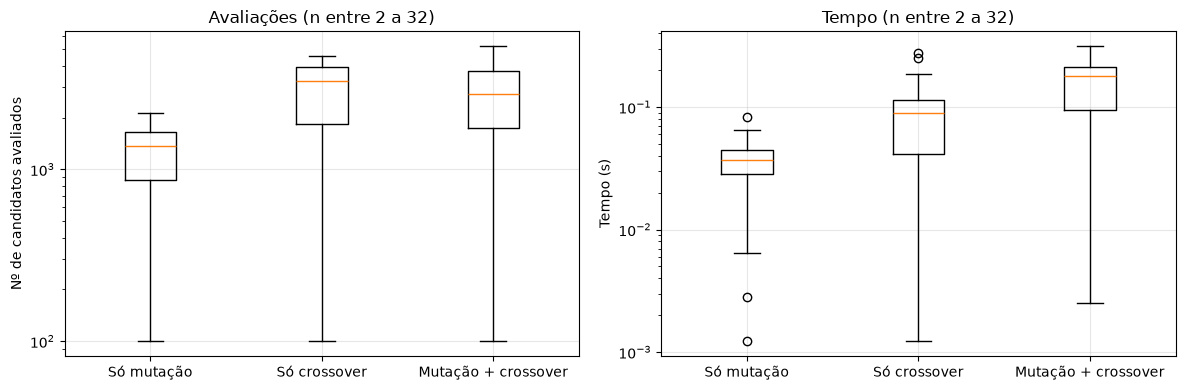

In [14]:
def plot_variants_v2(ea_results):
    labels = list(ea_results)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    configs = [
        (axes[0], [ea_results[k][0] for k in labels], "Nº de candidatos avaliados", "Avaliações"),
        (axes[1], [ea_results[k][1] for k in labels], "Tempo (s)", "Tempo"),
    ]
    for ax, data, ylabel, title in configs:
        ax.boxplot(data, tick_labels=labels)
        ax.set_yscale("log")
        ax.set_ylabel(ylabel)
        ax.set_title(f"{title} (n entre 2 a 32)")
        ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_variants_v2(ea4_results)

**Resultados e observações - Tamanho do alvo desconhecido (entre 2 e 32 bits):**

| Variante | Média de avaliações | Média de gerações | Tempo total (30 trials) | Target encontrado |
|---|---|---|---|---|
| Só mutação | 1 267 | 16.7 | 1.086 s | 30/30 |
| Só crossover | 2 744 | 37.8 | 2.733 s | 11/30 |
| Mutação + crossover | 2 611 | 35.9 | 4.436 s | 15/30 |

**Taxa de sucesso:** Só a variante com mutação encontrou o alvo em todos os trials. O crossover sozinho só o encontrou em 11 dos 30 e, combinado com a mutação, em 15 dos 30. Nos trials falhados a pesquisa terminou por estagnação (20 gerações sem melhoria) e não por encontrar o target.

**Avaliações e gerações:** Ao contrário do exercício anterior, o crossover não reduz o esforço: as variantes com crossover usam cerca de 2 vezes mais avaliações e mais do dobro das gerações. Estas médias incluem os trials falhados, que consomem pelo menos 20 gerações de estagnação.

**Dispersão:** Os resultados variam muito entre trials visto que o tamanho do target é diferente em cada um. 

**Conclusão:** Quando o tamanho do target é desconhecido, a mutação sozinha é a melhor variante: é a única que encontra sempre o target, e é também a mais rápida e a que avalia menos candidatos. 
